# Deep Learning: Sequence Models Hands-On (RNN, LSTM, GRU, Seq2Seq, Attention)

> **Who is this for:** a beginner who has read the theory notebook [`04_rnn_lstm_gru.ipynb`](04_rnn_lstm_gru.ipynb) and wants to *build and train* sequence models, plus BS/MS AI students revising BPTT, gating, seq2seq and attention for exams and interviews.
>
> **What you will learn**
> - A vanilla **RNN cell from scratch** in PyTorch, **back-propagation through time (BPTT)** written by hand and checked against autograd, and a gradient-norm plot that shows **vanishing and exploding gradients**
> - **LSTM and GRU cells from scratch**, verified against `nn.LSTM` / `nn.GRU` with copied weights
> - A **character-level language model** on a public-domain text, trained with **truncated BPTT**, and **temperature sampling**
> - **Padding, packing and masking** for variable-length sequence classification
> - A **seq2seq encoder-decoder** (string reversal) with **teacher forcing vs scheduled sampling**
> - **Bahdanau (additive) and Luong (multiplicative) attention**, attention heat-maps, and accuracy vs sequence length
> - **Greedy vs beam search** decoding
> - **Gradient clipping**, truncated BPTT, and when to choose RNNs vs Transformers vs state-space models today
>
> **Prerequisites:** [`04_rnn_lstm_gru.ipynb`](04_rnn_lstm_gru.ipynb) (formulas), [`18_neural_networks_from_scratch_numpy.ipynb`](18_neural_networks_from_scratch_numpy.ipynb) (backprop, layer API), [`00_start_here_pytorch_from_zero.ipynb`](00_start_here_pytorch_from_zero.ipynb) (tensors, `nn.Module`, training loop).
>
> **Time needed:** about 3-4 hours.
>
> **Runs on:** CPU, no API key, no downloads (all data is synthetic or embedded). Every model is tiny; the whole notebook runs in a few minutes.
>
> **Optional track:** this notebook is part of the **university-level fundamentals track**. We recommend it for BS/MS AI students and for interview prep. It is the hands-on companion to [`04_rnn_lstm_gru.ipynb`](04_rnn_lstm_gru.ipynb).

## Explained simply

Many kinds of data come **in order**: the letters of a word, the words of a sentence, the notes of a song, the daily price of a stock. A **recurrent neural network (RNN)** reads such a sequence one item at a time and keeps a small **memory** (a list of numbers called the *hidden state*) that it updates after every item, a bit like you keeping track of a story while reading. Plain RNNs forget quickly, so **LSTMs** and **GRUs** add little "gates", switches that learn what to keep, what to forget and what to output. To translate or transform one sequence into another, we use two RNNs: an **encoder** reads the input and a **decoder** writes the output. **Attention** lets the decoder look back at every input position instead of relying on one compressed memory.

Everyday pictures: **reading a mystery novel**, you keep a running memory of the clues and forget unimportant details (that is what the forget gate learns). **A simultaneous interpreter** listens to a whole sentence (encoder) and then speaks it in another language (decoder), glancing back at their notes for the word they are translating right now (attention).

**A tiny example.** Reverse the string `abc`. The encoder reads `a`, `b`, `c`. The decoder must output `c`, `b`, `a`. Without attention it has to squeeze all three letters into one memory vector; with attention, when it writes its first letter it simply "looks at" position 3 of the input, then position 2, then position 1. In Section 6 you will see this as a diagonal pattern in an attention heat-map.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| RNN / LSTM / GRU | reads a sequence step by step with a memory | phone keyboard next-word suggestions (older ones), speech recognition, sensor time series |
| Seq2seq + attention | one network reads, another writes while looking back at the input | the 2014-2017 generation of Google Translate; the idea behind Transformers |
| Beam search | keep the few best partial answers instead of only the single best | decoding in translation and speech systems, and an option in LLM text generation |

## Contents

1. Setup
2. A vanilla RNN from scratch, BPTT by hand, vanishing/exploding gradients
3. LSTM and GRU cells from scratch, checked against PyTorch
4. A character-level language model with truncated BPTT and temperature sampling
5. Variable-length sequences: padding, packing and masking
6. Seq2seq: encoder-decoder, teacher forcing vs scheduled sampling, Bahdanau and Luong attention
7. Greedy vs beam search
8. Gradient clipping, truncated BPTT, and RNNs vs Transformers vs SSMs
9. How this connects to modern AI
10. Recap, practice problems, further reading

## 1. Setup

> 💬 **In plain English:** load PyTorch, limit it to 2 CPU threads (these models are tiny), and fix the random seeds so your numbers match the text.

In [1]:
import math, time, random                      # standard library helpers
import numpy as np                             # small array maths
import pandas as pd                            # result tables
import matplotlib.pyplot as plt                # plots
import torch                                   # tensors + autograd
import torch.nn as nn                          # layers
import torch.nn.functional as F                # losses, softmax, ...

torch.set_num_threads(2)                       # tiny models: 2 threads are enough (and polite on shared machines)
SEED = 0
def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
seed_all()
pd.set_option("display.precision", 3)
print("torch", torch.__version__)

torch 2.12.1+cpu


## 2. A vanilla RNN from scratch

> 💬 **In plain English:** an RNN is one small layer applied again and again: at each step it mixes the new input with its previous memory to make a new memory.

**Definition (Elman RNN).** For inputs $x_1,\dots,x_T$ and an initial state $h_0$:

$$h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b), \qquad y_t = W_{hy}h_t + c.$$

The **same** weights are used at every time step (**weight sharing over time**), so the number of parameters does not depend on the sequence length. Shapes with batch size $B$, input size $D$, hidden size $H$: $x_t\in\mathbb{R}^{B\times D}$, $h_t\in\mathbb{R}^{B\times H}$, $W_{xh}\in\mathbb{R}^{H\times D}$, $W_{hh}\in\mathbb{R}^{H\times H}$.

**Unrolling.** Drawn over time, the RNN is just a very deep feed-forward network whose layers share weights:

```
 x1        x2        x3                 xT
  |         |         |                  |
h0 -> [cell] -> h1 -> [cell] -> h2 -> [cell] -> h3 ... -> [cell] -> hT  -> loss
           (same W_xh, W_hh, b in every box)
```

**Hand example** ($D=H=1$, $W_{xh}=1$, $W_{hh}=0.5$, $b=0$, $h_0=0$, inputs $1, 0, 0$):

| $t$ | $x_t$ | $W_{xh}x_t + W_{hh}h_{t-1}$ | $h_t = \tanh(\cdot)$ |
|---|---|---|---|
| 1 | 1 | $1 + 0 = 1$ | 0.7616 |
| 2 | 0 | $0 + 0.5(0.7616) = 0.3808$ | 0.3634 |
| 3 | 0 | $0 + 0.5(0.3634) = 0.1817$ | 0.1797 |

The memory of the first input fades by roughly half at every step: a first glimpse of the vanishing-memory problem.

In [2]:
class RNNCellScratch(nn.Module):
    def __init__(self, n_in, n_hidden):
        super().__init__()
        k = 1 / math.sqrt(n_hidden)                                   # PyTorch's default init range
        self.W_xh = nn.Parameter(torch.empty(n_hidden, n_in).uniform_(-k, k))
        self.W_hh = nn.Parameter(torch.empty(n_hidden, n_hidden).uniform_(-k, k))
        self.b = nn.Parameter(torch.zeros(n_hidden))

    def forward(self, x_t, h):                                        # x_t: (B, D), h: (B, H)
        return torch.tanh(x_t @ self.W_xh.T + h @ self.W_hh.T + self.b)


def unroll(cell, x, h0):                                              # x: (B, T, D) -> all hidden states (B, T, H)
    h, hs = h0, []
    for t in range(x.shape[1]):
        h = cell(x[:, t], h)
        hs.append(h)
    return torch.stack(hs, dim=1)


# Hand example
cell = RNNCellScratch(1, 1)
with torch.no_grad():
    cell.W_xh.fill_(1.0); cell.W_hh.fill_(0.5); cell.b.zero_()
print("h_1..h_3 =", unroll(cell, torch.tensor([[[1.0], [0.0], [0.0]]]), torch.zeros(1, 1)).flatten().detach().numpy().round(4))

# Compare with torch.nn.RNN using the same weights (nn.RNN has two biases; we put ours in one and zero the other).
seed_all()
B, T, D, H = 4, 7, 3, 5
cell = RNNCellScratch(D, H).double()
ref = nn.RNN(D, H, batch_first=True).double()
with torch.no_grad():
    ref.weight_ih_l0.copy_(cell.W_xh); ref.weight_hh_l0.copy_(cell.W_hh)
    ref.bias_ih_l0.copy_(cell.b); ref.bias_hh_l0.zero_()
x = torch.randn(B, T, D, dtype=torch.double); h0 = torch.zeros(B, H, dtype=torch.double)
ours = unroll(cell, x, h0); theirs, _ = ref(x, h0[None])
print("max |ours - nn.RNN| =", (ours - theirs).abs().max().item())

h_1..h_3 = [0.7616 0.3634 0.1797]
max |ours - nn.RNN| = 0.0


**What just happened?** The hand table's values 0.7616, 0.3634, 0.1797 are reproduced, and our loop equals `nn.RNN` to about $10^{-16}$ (float64 round-off). `nn.RNN` does exactly this loop, only in optimised C++.

### 2.1 Back-propagation through time (BPTT), by hand

> 💬 **In plain English:** BPTT is ordinary backprop on the unrolled network; because the same weights appear at every step, their gradient is the **sum** of the contributions from all steps.

Let $a_t = W_{xh}x_t + W_{hh}h_{t-1} + b$ and $h_t = \tanh(a_t)$. Suppose the loss depends on every $h_t$ and we are given $\partial L/\partial h_t$ "from above" (from the output layer). Going backwards from $t=T$ to $1$, with $\delta^{next} = 0$ at the start:

$$\bar h_t = \frac{\partial L}{\partial h_t}\Big|_{\text{output}} + \delta^{next}, \qquad \bar a_t = \bar h_t \odot (1-h_t^2),$$
$$\bar W_{xh} \mathrel{+}= \bar a_t^\top x_t,\qquad \bar W_{hh} \mathrel{+}= \bar a_t^\top h_{t-1},\qquad \bar b \mathrel{+}= \textstyle\sum_{batch}\bar a_t,\qquad \delta^{next} = \bar a_t W_{hh}.$$

The line $\delta^{next} = \bar a_t W_{hh}$ is the "through time" part: the gradient flows into the previous hidden state.

In [3]:
def bptt_manual(cell, x, h0, dH):
    # x: (B,T,D); dH: dL/dh_t coming from the outputs, shape (B,T,H). Returns grads for W_xh, W_hh, b.
    with torch.no_grad():
        hs = unroll(cell, x, h0)                                   # forward pass, keep every h_t
        dW_xh = torch.zeros_like(cell.W_xh); dW_hh = torch.zeros_like(cell.W_hh); db = torch.zeros_like(cell.b)
        d_next = torch.zeros_like(h0)
        for t in reversed(range(x.shape[1])):
            h_t = hs[:, t]
            h_prev = hs[:, t - 1] if t > 0 else h0
            dh = dH[:, t] + d_next                                 # from the output at t + from step t+1
            da = dh * (1 - h_t ** 2)                               # through tanh
            dW_xh += da.T @ x[:, t]                                # weight sharing: ADD over time
            dW_hh += da.T @ h_prev
            db += da.sum(0)
            d_next = da @ cell.W_hh                                # flows back to h_{t-1}
    return dW_xh, dW_hh, db

dH = torch.randn(B, T, H, dtype=torch.double)
manual = bptt_manual(cell, x, h0, dH)
cell.zero_grad()
(unroll(cell, x, h0) * dH).sum().backward()                        # autograd on L = sum(h_t * dH_t)
for name, g_manual, p in zip(["W_xh", "W_hh", "b"], manual, [cell.W_xh, cell.W_hh, cell.b]):
    print(f"{name}: max |manual - autograd| = {(g_manual - p.grad).abs().max().item():.1e}")

W_xh: max |manual - autograd| = 1.8e-15
W_hh: max |manual - autograd| = 4.4e-16
b: max |manual - autograd| = 1.8e-15


**What just happened?** Our hand-written BPTT gives the same gradients as autograd (differences around $10^{-16}$). **Cost:** forward and backward are both $O(T\cdot(DH + H^2))$ per sequence, and BPTT must **store all $T$ hidden states**, so memory grows linearly with sequence length. Section 8 shows how *truncated* BPTT caps that.

### 2.2 Why gradients vanish or explode

> 💬 **In plain English:** the gradient that travels from step $T$ back to step $t$ is multiplied by the same matrix again and again; numbers multiplied many times either shrink to zero or blow up.

From the recursion, $\dfrac{\partial h_T}{\partial h_t} = \prod_{k=t+1}^{T} \operatorname{diag}(1-h_k^2)\,W_{hh}$. Its norm is at most $\big(\max|1-h^2|\cdot\lVert W_{hh}\rVert\big)^{T-t} \le \lVert W_{hh}\rVert^{T-t}$. So if the largest singular value of $W_{hh}$ is below 1 the gradient **vanishes exponentially** with distance; if it is well above 1 (and tanh is not saturated) it can **explode** (Pascanu, Mikolov & Bengio, 2013).

We measure $\lVert\partial L/\partial h_t\rVert$ for $L = \sum h_T$ on a 60-step sequence, for recurrent matrices scaled to different spectral norms.

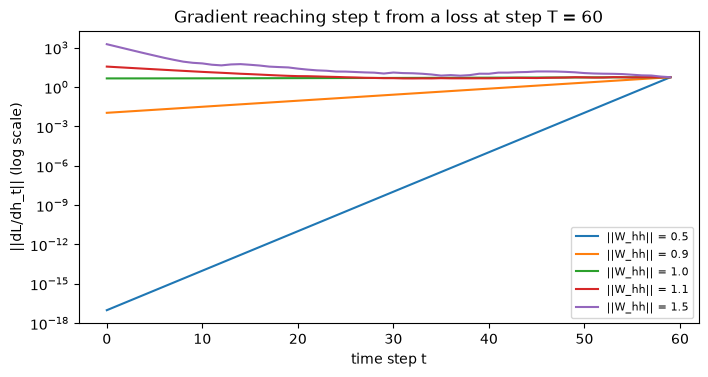

||W_hh||=0.5:  ||dL/dh_1|| / ||dL/dh_60|| = 1.72e-18
||W_hh||=0.9:  ||dL/dh_1|| / ||dL/dh_60|| = 1.93e-03
||W_hh||=1.5:  ||dL/dh_1|| / ||dL/dh_60|| = 3.29e+02


In [4]:
def grad_norms_over_time(scale, T=60, H=32, seed=0):
    g = torch.Generator().manual_seed(seed)
    cell = RNNCellScratch(1, H)
    with torch.no_grad():
        Q, _ = torch.linalg.qr(torch.randn(H, H, generator=g))       # random orthogonal matrix: all singular values = 1
        cell.W_hh.copy_(scale * Q)                                    # so ||W_hh|| = scale exactly
        cell.W_xh.copy_(torch.randn(H, 1, generator=g) * 0.1)
    x = torch.randn(1, T, 1, generator=g) * 0.1                       # small inputs: tanh stays roughly linear
    h, hs = torch.zeros(1, H), []
    for t in range(T):
        h = cell(x[:, t], h); h.retain_grad(); hs.append(h)          # keep the gradient of every h_t
    hs[-1].sum().backward()
    return [hh.grad.norm().item() for hh in hs]

plt.figure(figsize=(8, 3.8))
for scale in [0.5, 0.9, 1.0, 1.1, 1.5]:
    plt.semilogy(grad_norms_over_time(scale), label=f"||W_hh|| = {scale}")
plt.xlabel("time step t"); plt.ylabel("||dL/dh_t|| (log scale)"); plt.legend(fontsize=8)
plt.title("Gradient reaching step t from a loss at step T = 60"); plt.show()
for scale in [0.5, 0.9, 1.5]:
    g = grad_norms_over_time(scale); print(f"||W_hh||={scale}:  ||dL/dh_1|| / ||dL/dh_60|| = {g[0] / g[-1]:.2e}")

**What just happened?** For norms below 1 each curve is a straight line on the log scale, i.e. the gradient shrinks **exponentially** with the distance $T-t$. With $\lVert W_{hh}\rVert = 0.5$ the gradient that reaches step 1 is about $10^{-18}$ of the gradient at step 60, so the RNN cannot learn that anything early in the sequence mattered; even $0.9$ loses a factor of about 500. With $1.5$ the gradient grows instead (**exploding**), here by a factor of about 330, and then flattens: as the hidden values grow, tanh saturates and its slope $1-h^2$ shrinks, which caps the growth in this toy (with ReLU-like units or larger inputs, explosions can be far worse). Only near 1 does the gradient travel unchanged. Real RNNs drift away from 1 during training, which is why plain RNNs struggle with dependencies longer than a few dozen steps.

> 🎓 **Exam / interview tip:** "Why do LSTMs help with vanishing gradients?" The cell state is updated **additively**, $c_t = f_t\odot c_{t-1} + i_t\odot g_t$, so $\partial c_t/\partial c_{t-1} = \operatorname{diag}(f_t)$ with no squashing matrix product; when the forget gate is near 1 the gradient passes almost unchanged (the "constant error carousel"). Exploding gradients are handled separately, with **gradient clipping**.

## 3. LSTM and GRU cells from scratch

> 💬 **In plain English:** gates are sigmoids (numbers between 0 and 1) that act like volume knobs: how much of the old memory to keep, how much new information to write, how much of the memory to show.

**LSTM** (Hochreiter & Schmidhuber, 1997; forget gate by Gers et al., 2000). With $\sigma$ the sigmoid, and PyTorch's gate order **i, f, g, o**:

| Quantity | Formula | Role |
|---|---|---|
| input gate | $i_t = \sigma(W_{ii}x_t + b_{ii} + W_{hi}h_{t-1} + b_{hi})$ | how much new content to write |
| forget gate | $f_t = \sigma(W_{if}x_t + b_{if} + W_{hf}h_{t-1} + b_{hf})$ | how much old memory to keep |
| candidate | $g_t = \tanh(W_{ig}x_t + b_{ig} + W_{hg}h_{t-1} + b_{hg})$ | the new content |
| output gate | $o_t = \sigma(W_{io}x_t + b_{io} + W_{ho}h_{t-1} + b_{ho})$ | how much memory to expose |
| cell state | $c_t = f_t\odot c_{t-1} + i_t\odot g_t$ | the long-term memory (additive update) |
| hidden state | $h_t = o_t\odot\tanh(c_t)$ | the short-term output |

**GRU** (Cho et al., 2014), gate order **r, z, n** in PyTorch:

| Quantity | Formula |
|---|---|
| reset gate | $r_t = \sigma(W_{ir}x_t + b_{ir} + W_{hr}h_{t-1} + b_{hr})$ |
| update gate | $z_t = \sigma(W_{iz}x_t + b_{iz} + W_{hz}h_{t-1} + b_{hz})$ |
| candidate | $n_t = \tanh(W_{in}x_t + b_{in} + r_t\odot(W_{hn}h_{t-1} + b_{hn}))$ |
| new state | $h_t = (1-z_t)\odot n_t + z_t\odot h_{t-1}$ |

The GRU merges cell and hidden state and uses 3 weight blocks instead of 4, so it has 25% fewer parameters than an LSTM of the same size.

In [5]:
class LSTMCellScratch(nn.Module):
    def __init__(self, n_in, n_hidden):
        super().__init__()
        k = 1 / math.sqrt(n_hidden)
        self.W_ih = nn.Parameter(torch.empty(4 * n_hidden, n_in).uniform_(-k, k))      # [i; f; g; o] stacked
        self.W_hh = nn.Parameter(torch.empty(4 * n_hidden, n_hidden).uniform_(-k, k))
        self.b_ih = nn.Parameter(torch.empty(4 * n_hidden).uniform_(-k, k))
        self.b_hh = nn.Parameter(torch.empty(4 * n_hidden).uniform_(-k, k))

    def forward(self, x_t, state):
        h, c = state
        gates = x_t @ self.W_ih.T + self.b_ih + h @ self.W_hh.T + self.b_hh            # all four gates in one matmul
        i, f, g, o = gates.chunk(4, dim=1)
        i, f, o = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o)
        g = torch.tanh(g)
        c = f * c + i * g                                                                # additive memory update
        h = o * torch.tanh(c)
        return h, c


class GRUCellScratch(nn.Module):
    def __init__(self, n_in, n_hidden):
        super().__init__()
        k = 1 / math.sqrt(n_hidden)
        self.W_ih = nn.Parameter(torch.empty(3 * n_hidden, n_in).uniform_(-k, k))      # [r; z; n]
        self.W_hh = nn.Parameter(torch.empty(3 * n_hidden, n_hidden).uniform_(-k, k))
        self.b_ih = nn.Parameter(torch.empty(3 * n_hidden).uniform_(-k, k))
        self.b_hh = nn.Parameter(torch.empty(3 * n_hidden).uniform_(-k, k))

    def forward(self, x_t, h):
        gi = x_t @ self.W_ih.T + self.b_ih
        gh = h @ self.W_hh.T + self.b_hh
        i_r, i_z, i_n = gi.chunk(3, dim=1)
        h_r, h_z, h_n = gh.chunk(3, dim=1)
        r = torch.sigmoid(i_r + h_r)
        z = torch.sigmoid(i_z + h_z)
        n = torch.tanh(i_n + r * h_n)                     # reset gate scales the recurrent part only
        return (1 - z) * n + z * h


def copy_weights(scratch, ref):
    with torch.no_grad():
        scratch.W_ih.copy_(ref.weight_ih_l0); scratch.W_hh.copy_(ref.weight_hh_l0)
        scratch.b_ih.copy_(ref.bias_ih_l0); scratch.b_hh.copy_(ref.bias_hh_l0)

seed_all()
x = torch.randn(B, T, D, dtype=torch.double)
lstm_ref, gru_ref = nn.LSTM(D, H, batch_first=True).double(), nn.GRU(D, H, batch_first=True).double()
lstm_s, gru_s = LSTMCellScratch(D, H).double(), GRUCellScratch(D, H).double()
copy_weights(lstm_s, lstm_ref); copy_weights(gru_s, gru_ref)

h = c = torch.zeros(B, H, dtype=torch.double); outs = []
for t in range(T):
    h, c = lstm_s(x[:, t], (h, c)); outs.append(h)
ref_out, (h_ref, c_ref) = lstm_ref(x)
print("LSTM: max |outputs diff| =", (torch.stack(outs, 1) - ref_out).abs().max().item(),
      " |final c diff| =", (c - c_ref[0]).abs().max().item())

h = torch.zeros(B, H, dtype=torch.double); outs = []
for t in range(T):
    h = gru_s(x[:, t], h); outs.append(h)
ref_out, _ = gru_ref(x)
print("GRU : max |outputs diff| =", (torch.stack(outs, 1) - ref_out).abs().max().item())

count = lambda m: sum(p.numel() for p in m.parameters())
print(pd.Series({"RNN": count(nn.RNN(D, H)), "GRU": count(gru_ref), "LSTM": count(lstm_ref)},
                name=f"parameters (D={D}, H={H})"))

LSTM: max |outputs diff| = 1.1102230246251565e-16  |final c diff| = 5.551115123125783e-17
GRU : max |outputs diff| = 1.1102230246251565e-16
RNN      50
GRU     150
LSTM    200
Name: parameters (D=3, H=5), dtype: int64


**What just happened?** Both scratch cells reproduce PyTorch exactly (differences around $10^{-16}$), which confirms the gate equations and PyTorch's gate order. Parameter counts follow the formula (number of gate blocks) × $(HD + H^2 + 2H)$: 1 block for the RNN, 3 for the GRU, 4 for the LSTM: $1\times 50 = 50$, $3\times50 = 150$, $4\times50 = 200$ with $D=3$, $H=5$.

### 3.1 Gradient flow: RNN vs LSTM vs GRU

We repeat the gradient-over-time measurement for all three cells at their default initialisation. Here we ask how strongly the final output depends on each *input* $x_t$, i.e. $\lVert\partial L/\partial x_t\rVert$ with $L = \sum h_T$.

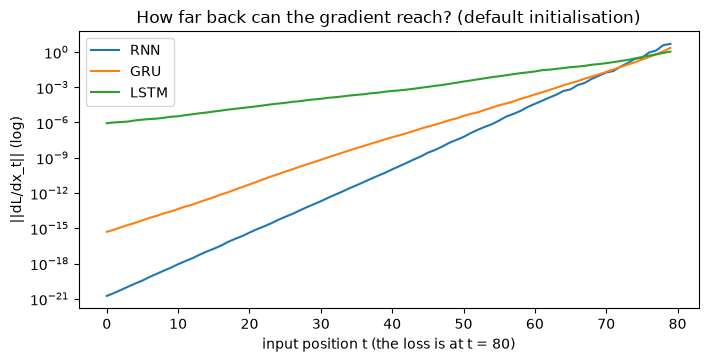

RNN : gradient at t=40 is 2.1e-11 of the gradient at t=80
GRU : gradient at t=40 is 2.5e-08 of the gradient at t=80
LSTM: gradient at t=40 is 4.5e-04 of the gradient at t=80


In [6]:
def input_grad_profile(kind, T=80, H=64, seed=1):
    torch.manual_seed(seed)
    net = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[kind](8, H, batch_first=True)
    if kind == "LSTM":
        with torch.no_grad():
            net.bias_ih_l0[H:2 * H].fill_(1.0)          # common trick: forget-gate bias 1 -> remember by default
    x = torch.randn(16, T, 8, requires_grad=True)
    out, _ = net(x)
    out[:, -1].sum().backward()
    return x.grad.norm(dim=(0, 2)).numpy()

plt.figure(figsize=(8, 3.6))
for kind in ["RNN", "GRU", "LSTM"]:
    plt.semilogy(input_grad_profile(kind), label=kind)
plt.xlabel("input position t (the loss is at t = 80)"); plt.ylabel("||dL/dx_t|| (log)")
plt.title("How far back can the gradient reach? (default initialisation)"); plt.legend(); plt.show()
for kind in ["RNN", "GRU", "LSTM"]:
    p = input_grad_profile(kind); print(f"{kind:4s}: gradient at t=40 is {p[40] / p[-1]:.1e} of the gradient at t=80")

**What just happened?** At initialisation, the gradient that reaches an input 40 steps back is about $10^{-11}$ of the gradient at the last step for the RNN, $10^{-8}$ for the GRU and $10^{-4}$ for the LSTM with forget bias 1: about seven orders of magnitude better than the plain RNN. The gated cells keep a much larger fraction of the gradient over long distances, because their memory is updated by gated **addition** rather than repeated multiplication by $W_{hh}$ and tanh.

> ⚠️ **Common mistake:** assuming LSTMs *solve* long-range dependencies. They push the horizon from tens to a few hundred steps in practice; for thousands of steps, attention (Transformers) or state-space models are used today (Section 8).

## 4. A character-level language model

> 💬 **In plain English:** we show the network a text one character at a time and train it to guess the next character; then we let it write by feeding its own guesses back in.

**Definition.** A language model assigns a probability to a sequence by the chain rule, $p(c_1,\dots,c_T) = \prod_t p(c_t\mid c_{<t})$. An RNN models $p(c_t\mid c_{<t})$ with a softmax over the vocabulary computed from $h_{t-1}$. Training minimises the average **cross-entropy** (negative log-likelihood) per character; $\exp(\text{loss})$ is the **perplexity** (the effective number of equally likely choices) and $\text{loss}/\ln 2$ is **bits per character**.

Our corpus is the opening of Lewis Carroll's *Alice's Adventures in Wonderland* (1865, public domain), embedded below so nothing is downloaded.

In [7]:
TEXT = (
    "Alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: "
    "once or twice she had peeped into the book her sister was reading, but it had no pictures or conversations "
    "in it, 'and what is the use of a book,' thought Alice 'without pictures or conversations?' "
    "So she was considering in her own mind (as well as she could, for the hot day made her feel very sleepy and "
    "stupid), whether the pleasure of making a daisy-chain would be worth the trouble of getting up and picking "
    "the daisies, when suddenly a White Rabbit with pink eyes ran close by her. "
    "There was nothing so very remarkable in that; nor did Alice think it so very much out of the way to hear the "
    "Rabbit say to itself, 'Oh dear! Oh dear! I shall be late!' (when she thought it over afterwards, it occurred "
    "to her that she ought to have wondered at this, but at the time it all seemed quite natural); but when the "
    "Rabbit actually took a watch out of its waistcoat-pocket, and looked at it, and then hurried on, Alice started "
    "to her feet, for it flashed across her mind that she had never before seen a rabbit with either a "
    "waistcoat-pocket, or a watch to take out of it, and burning with curiosity, she ran across the field after it, "
    "and fortunately was just in time to see it pop down a large rabbit-hole under the hedge. "
    "In another moment down went Alice after it, never once considering how in the world she was to get out again. "
    "The rabbit-hole went straight on like a tunnel for some way, and then dipped suddenly down, so suddenly that "
    "Alice had not a moment to think about stopping herself before she found herself falling down a very deep well."
)
chars = sorted(set(TEXT))
c2i = {c: i for i, c in enumerate(chars)}; i2c = {i: c for c, i in c2i.items()}
data = torch.tensor([c2i[c] for c in TEXT])
print(f"{len(TEXT)} characters, vocabulary of {len(chars)} symbols")
print("uniform-guess loss = ln(V) =", round(math.log(len(chars)), 3))

1656 characters, vocabulary of 42 symbols
uniform-guess loss = ln(V) = 3.738


**Truncated BPTT.** Instead of back-propagating through the whole text, we cut it into $B$ parallel streams and process them in chunks of $k=32$ characters. The hidden state is **carried** from one chunk to the next (so the model still sees long context in the forward pass) but **detached** (so gradients only flow back 32 steps). Memory is $O(k)$ instead of $O(T)$.

```
stream 0: |chunk 1 ----32----|chunk 2 ----32----|chunk 3 ...
                             ^ h carried forward, gradient cut here (h = h.detach())
```

trained in 6.3s; final loss 0.010 nats/char = 0.01 bits/char, perplexity 1.01


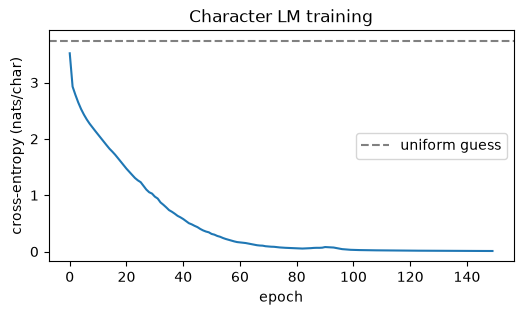

In [8]:
class CharLM(nn.Module):
    def __init__(self, vocab, emb=32, hidden=128):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb)            # character id -> vector
        self.lstm = nn.LSTM(emb, hidden, batch_first=True)
        self.head = nn.Linear(hidden, vocab)           # hidden state -> next-character logits

    def forward(self, idx, state=None):
        out, state = self.lstm(self.emb(idx), state)
        return self.head(out), state


def train_char_lm(epochs=150, n_streams=8, k=32, lr=3e-3, seed=SEED):
    seed_all(seed)
    model = CharLM(len(chars)); opt = torch.optim.Adam(model.parameters(), lr=lr)
    L = (len(data) - 1) // n_streams
    xs = data[:n_streams * L].view(n_streams, L)              # B parallel streams
    ys = data[1:n_streams * L + 1].view(n_streams, L)          # targets = next character
    history = []
    for epoch in range(epochs):
        state, losses = None, []
        for start in range(0, L - 1, k):
            x, y = xs[:, start:start + k], ys[:, start:start + k]
            if state is not None:
                state = tuple(s.detach() for s in state)     # truncated BPTT: keep the values, cut the graph
            logits, state = model(x, state)
            loss = F.cross_entropy(logits.reshape(-1, len(chars)), y.reshape(-1))
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # gradient clipping (Section 8)
            opt.step(); losses.append(loss.item())
        history.append(np.mean(losses))
    return model, history

t0 = time.perf_counter()
char_lm, char_hist = train_char_lm()
print(f"trained in {time.perf_counter() - t0:.1f}s; final loss {char_hist[-1]:.3f} nats/char "
      f"= {char_hist[-1] / math.log(2):.2f} bits/char, perplexity {math.exp(char_hist[-1]):.2f}")
plt.figure(figsize=(6, 3)); plt.plot(char_hist); plt.axhline(math.log(len(chars)), ls="--", c="gray", label="uniform guess")
plt.xlabel("epoch"); plt.ylabel("cross-entropy (nats/char)"); plt.title("Character LM training"); plt.legend(); plt.show()

### 4.1 Temperature sampling

> 💬 **In plain English:** temperature is a creativity knob. Low temperature: always pick the safest next letter (repetitive). High temperature: take more risks (creative, then nonsense).

Divide the logits by a temperature $\tau$ before the softmax: $p_i \propto \exp(z_i/\tau)$. $\tau\to0$ approaches greedy (arg-max) decoding; $\tau=1$ samples from the model's distribution; $\tau>1$ flattens it towards uniform.

In [9]:
@torch.no_grad()
def sample(model, prompt, n=160, temperature=1.0, seed=0):
    g = torch.Generator().manual_seed(seed)
    idx = torch.tensor([[c2i[c] for c in prompt]])
    logits, state = model(idx)                                   # read the prompt
    out = list(prompt)
    for _ in range(n):
        probs = F.softmax(logits[0, -1] / temperature, dim=-1)   # temperature-scaled distribution
        nxt = torch.multinomial(probs, 1, generator=g).item()    # draw the next character
        out.append(i2c[nxt])
        logits, state = model(torch.tensor([[nxt]]), state)      # feed it back in
    return "".join(out)

for tau in [0.3, 1.0, 1.8]:
    print(f"--- temperature {tau} ---\n{sample(char_lm, 'Alice ', temperature=tau)}\n")

# Entropy of the next-character distribution after the prompt, as a function of temperature
with torch.no_grad():
    z = char_lm(torch.tensor([[c2i[c] for c in "Alice "]]))[0][0, -1]
for tau in [0.3, 1.0, 1.8]:
    p = F.softmax(z / tau, -1); print(f"tau={tau}: entropy {-(p * p.log()).sum().item():.2f} nats, top-1 prob {p.max().item():.2f}")

--- temperature 0.3 ---
Alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: once or twice she had peeped into the book her sister was rea

--- temperature 1.0 ---
Alice was beginning to get very tired of sitting by her sister on see ry ure he tised of iste son the suddenly radd she ,able of getting uppyand and then hurried on, 

--- temperature 1.8 ---
Alice wond the fithe Ius, anatrind ?hay so( very nSele ros, 'Ohed sleary upede!et it it in the vicred acrosshenr ous, when surled of sit seay woudes or hor wwin her i

tau=0.3: entropy 0.00 nats, top-1 prob 1.00
tau=1.0: entropy 0.07 nats, top-1 prob 0.99
tau=1.8: entropy 0.80 nats, top-1 prob 0.85


**What just happened?** The training loss falls far below the uniform-guess line. At low temperature the model reproduces long stretches of the text almost verbatim (it has largely **memorised** this tiny corpus, which is expected with about 1,800 characters and ~90k parameters); at $\tau = 1$ it mostly follows the text with occasional detours; at $\tau = 1.8$ it produces English-looking gibberish. The entropy numbers show why: raising $\tau$ spreads probability over more characters.

> 🎓 **Exam / interview tip:** with a real corpus you must report loss on **held-out** text; training perplexity on a memorised text says nothing about generalisation. Our purpose here is only to see the mechanics.

## 5. Variable-length sequences: padding, packing and masking

> 💬 **In plain English:** sequences in a batch have different lengths, so we fill the short ones with a dummy PAD symbol. We must then make sure the model never "reads" those fillers as if they were real data.

**Task (synthetic, sentiment-like).** Tokens are words from a toy vocabulary with 4 "positive", 4 "negative" and 12 "neutral" words. A sequence of length 3-30 is labelled **1** if it contains more positive than negative words, else **0** (ties are skipped). Batches are padded at the end with `PAD = 0`.

Four ways to read the batch with a GRU:

| Variant | What it does | Problem / benefit |
|---|---|---|
| (a) **naive last step** | run over the padded batch, use the hidden state at the *last padded position* | the state must survive all the PAD steps after a short sequence |
| (b) **unmasked mean** | average the GRU outputs over *all* positions, PAD included | the average is diluted by PAD states, so it depends on how much padding there is |
| (c) **packed** | `pack_padded_sequence` tells the GRU each true length; use the true final state $h_n$ | correct by construction, and skips wasted computation |
| (d) **masked mean** | average the outputs only over real positions (mask) | correct by construction; uses all states, not just the last |

In [10]:
PAD_TOK, N_WORDS = 0, 20                       # ids 1..4 positive, 5..8 negative, 9..20 neutral
POS, NEG = set(range(1, 5)), set(range(5, 9))

def make_sentiment_batch(n, rng, lo=3, hi=30):
    seqs, labels = [], []
    while len(seqs) < n:
        L = int(rng.integers(lo, hi + 1))
        s = rng.integers(1, N_WORDS + 1, size=L)
        p, q = sum(int(t) in POS for t in s), sum(int(t) in NEG for t in s)
        if p == q:
            continue                            # skip ties
        seqs.append(s); labels.append(int(p > q))
    lens = torch.tensor([len(s) for s in seqs])
    X = torch.full((n, int(lens.max())), PAD_TOK, dtype=torch.long)
    for i, s in enumerate(seqs):
        X[i, :len(s)] = torch.tensor(s)         # pad at the end
    return X, lens, torch.tensor(labels)


class SeqClassifier(nn.Module):
    def __init__(self, mode, emb=16, hidden=32):
        super().__init__()
        self.mode = mode
        self.emb = nn.Embedding(N_WORDS + 1, emb, padding_idx=PAD_TOK)
        self.gru = nn.GRU(emb, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 2)

    def forward(self, X, lens):
        e = self.emb(X)
        if self.mode == "packed":
            packed = nn.utils.rnn.pack_padded_sequence(e, lens, batch_first=True, enforce_sorted=False)
            _, h_n = self.gru(packed)                       # h_n = state after each sequence's TRUE last token
            return self.head(h_n[0])
        out, _ = self.gru(e)                                # (B, T, H), includes PAD steps
        if self.mode == "naive":
            return self.head(out[:, -1])                    # last padded position: wrong for short sequences
        if self.mode == "unmasked":
            return self.head(out.mean(1))                   # averages PAD states too: a common bug
        mask = (X != PAD_TOK).unsqueeze(-1).float()         # (B, T, 1): 1 for real tokens, 0 for PAD
        return self.head((out * mask).sum(1) / mask.sum(1))  # masked mean


def train_classifier(mode, steps=300, seed=SEED):
    seed_all(seed); rng = np.random.default_rng(seed)
    model = SeqClassifier(mode); opt = torch.optim.Adam(model.parameters(), lr=5e-3)
    for _ in range(steps):
        X, lens, y = make_sentiment_batch(64, rng)
        loss = F.cross_entropy(model(X, lens), y)
        opt.zero_grad(); loss.backward(); opt.step()
    return model

rng_test = np.random.default_rng(999)
X_te, lens_te, y_te = make_sentiment_batch(2000, rng_test)
buckets = pd.cut(lens_te.numpy(), [2, 10, 20, 30], labels=["3-10", "11-20", "21-30"])
rows, classifiers = {}, {}
for mode in ["naive", "unmasked", "packed", "masked"]:
    t0 = time.perf_counter()
    clf = train_classifier(mode)
    with torch.no_grad():
        correct = (clf(X_te, lens_te).argmax(1) == y_te).numpy()
    row = {"overall": correct.mean()}
    row.update({f"len {b}": correct[buckets == b].mean() for b in ["3-10", "11-20", "21-30"]})
    row["train time (s)"] = time.perf_counter() - t0
    rows[mode] = row
    classifiers[mode] = clf
print("test accuracy by true sequence length (the test batch is padded to length 30):")
print(pd.DataFrame(rows).T)

test accuracy by true sequence length (the test batch is padded to length 30):
          overall  len 3-10  len 11-20  len 21-30  train time (s)
naive       0.998     1.000      1.000      0.994           4.194
unmasked    0.989     0.996      0.999      0.974           4.519
packed      1.000     1.000      1.000      1.000           4.939
masked      0.998     1.000      0.997      0.996           4.437


With test batches padded like the training batches, all four variants look excellent. But padding is an accident of batching (it depends on the longest sequence in the batch), so a correct model must give **the same answer however much padding follows a sequence**. Let us pad the same test sequences to 60 and 120 positions.

In [11]:
def pad_to(X, length):
    out = torch.full((X.shape[0], length), PAD_TOK, dtype=torch.long)
    out[:, :X.shape[1]] = X
    return out

pad_rows = {}
for mode, clf in classifiers.items():
    with torch.no_grad():
        base = clf(X_te, lens_te).argmax(1)
        pad_rows[mode] = {f"padded to {n}": (clf(pad_to(X_te, n), lens_te).argmax(1) == y_te).float().mean().item()
                          for n in [30, 60, 120]}
        pad_rows[mode]["predictions changed by padding to 120"] = (clf(pad_to(X_te, 120), lens_te).argmax(1) != base).float().mean().item()
print(pd.DataFrame(pad_rows).T)

          padded to 30  padded to 60  padded to 120  \
naive            0.998         0.998          0.998   
unmasked         0.988         0.945          0.919   
packed           1.000         1.000          1.000   
masked           0.998         0.998          0.998   

          predictions changed by padding to 120  
naive                                     0.000  
unmasked                                  0.089  
packed                                    0.000  
masked                                    0.000  


**What just happened?** The packed and masked models are, by construction, unaffected by extra padding: their predictions do not change at all. The **unmasked mean** is the classic bug: with more padding, more PAD states are averaged in, the sentence representation drifts: accuracy falls from about 99% to about 92% at 120 positions and roughly 9% of the predictions flip, even though the validation score at the training padding looked fine. The **naive last-step** model survived in this run: its GRU learned to keep its state almost unchanged on PAD steps (the PAD embedding is a zero vector, so the update gate can learn to "hold"). That is luck, not design; with a plain RNN, an LSTM without that behaviour, or a non-zero PAD embedding, the same shortcut often breaks. Masks and packing make correctness a property of the code instead of something the model may or may not learn.

> ⚠️ **Common mistake:** computing a sequence-labelling loss (one label per token) over PAD positions. Use `ignore_index=PAD` in `F.cross_entropy` or multiply the per-token loss by the mask before averaging. The same idea appears in Transformers as the **padding mask** (attention scores to PAD positions are set to $-\infty$ before the softmax), which we also use in the attention decoder below.

## 6. Seq2seq: encoder-decoder with and without attention

> 💬 **In plain English:** the encoder reads the whole input and summarises it; the decoder writes the output one token at a time, each time feeding back the token it just wrote.

**Task:** reverse a string of letters `a`-`j`, e.g. `cabhd → dhbac`. Training lengths are 3-10. Special tokens: `PAD=0`, `SOS=1` (start), `EOS=2` (end).

**Model (Sutskever et al., 2014; Cho et al., 2014).**
- **Encoder:** embedding + GRU, packed by true length; outputs $h^{enc}_1..h^{enc}_S$ and the final state.
- **Decoder:** a `GRUCell` initialised with the encoder's final state. At step $t$ its input is the previous output token $y_{t-1}$ (`SOS` at $t=1$); a linear layer gives logits over the vocabulary.
- **Loss:** cross-entropy over target tokens (including `EOS`), ignoring `PAD`.

**Teacher forcing vs scheduled sampling.** During training, what is fed back as $y_{t-1}$?
- **Teacher forcing:** always the *true* previous token. Fast and stable, but at test time the model must consume its *own* predictions, which it never practised (**exposure bias**).
- **Scheduled sampling** (Bengio et al., 2015): with probability $\epsilon_i$ feed the true token, otherwise the model's own prediction; $\epsilon_i$ decays during training (here linearly from 1 to 0.5).

**Attention.** Instead of only the final encoder state, at each decoder step compute weights $\alpha_{tj}$ over all encoder states and a **context vector** $c_t = \sum_j \alpha_{tj} h^{enc}_j$:

| | Score $e_{tj}$ | When it is computed | Used for |
|---|---|---|---|
| **Bahdanau** (additive, 2015) | $v^\top\tanh(W s_{t-1} + U h^{enc}_j)$ | *before* the GRU step, from the previous state | $c_t$ is fed into the GRU with $y_{t-1}$, and into the output layer |
| **Luong** ("general", multiplicative, 2015) | $s_t^\top W_a h^{enc}_j$ | *after* the GRU step | $\tilde s_t = \tanh(W_c[s_t; c_t])$ feeds the output layer |

In both cases $\alpha_{t\cdot} = \operatorname{softmax}_j(e_{tj})$ with PAD positions masked to $-\infty$.

In [12]:
PAD, SOS, EOS = 0, 1, 2
LETTERS = "abcdefghij"
s2i = {c: i + 3 for i, c in enumerate(LETTERS)}; i2s = {i: c for c, i in s2i.items()}
VOCAB = len(LETTERS) + 3

def make_reverse_batch(n, lo, hi, rng):
    lens = rng.integers(lo, hi + 1, size=n)
    srcs = [[s2i[c] for c in rng.choice(list(LETTERS), size=L)] for L in lens]
    S = int(lens.max())
    src = torch.full((n, S), PAD, dtype=torch.long); tgt = torch.full((n, S + 1), PAD, dtype=torch.long)
    for i, s in enumerate(srcs):
        src[i, :len(s)] = torch.tensor(s)
        tgt[i, :len(s) + 1] = torch.tensor(s[::-1] + [EOS])     # reversed + end token
    return src, torch.tensor(lens), tgt

decode_str = lambda ids: "".join(i2s.get(int(i), "") for i in ids if int(i) not in (PAD, EOS))
src, lens, tgt = make_reverse_batch(3, 3, 6, np.random.default_rng(0))
for s, t in zip(src, tgt):
    print(decode_str(s), "->", decode_str(t), "  target ids:", t.tolist())

cdaaab -> baaadc   target ids: [4, 3, 3, 3, 6, 5, 2]
igjfg -> gfjgi   target ids: [9, 8, 12, 9, 11, 2, 0]
jhgff -> ffghj   target ids: [8, 8, 9, 10, 12, 2, 0]


In [13]:
class Encoder(nn.Module):
    def __init__(self, emb=32, hidden=64):
        super().__init__()
        self.emb = nn.Embedding(VOCAB, emb, padding_idx=PAD)
        self.rnn = nn.GRU(emb, hidden, batch_first=True)

    def forward(self, src, lens):
        packed = nn.utils.rnn.pack_padded_sequence(self.emb(src), lens, batch_first=True, enforce_sorted=False)
        out, h = self.rnn(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=src.shape[1])
        return out, h[0]                                    # all states (B,S,H), final state (B,H)


class Decoder(nn.Module):
    def __init__(self, attn=None, emb=32, hidden=64):
        super().__init__()
        self.attn = attn
        self.emb = nn.Embedding(VOCAB, emb)
        self.cell = nn.GRUCell(emb + (hidden if attn == "bahdanau" else 0), hidden)
        if attn == "bahdanau":
            self.W = nn.Linear(hidden, hidden, bias=False); self.U = nn.Linear(hidden, hidden, bias=False)
            self.v = nn.Linear(hidden, 1, bias=False); self.out = nn.Linear(2 * hidden, VOCAB)
        elif attn == "luong":
            self.Wa = nn.Linear(hidden, hidden, bias=False); self.Wc = nn.Linear(2 * hidden, hidden)
            self.out = nn.Linear(hidden, VOCAB)
        else:
            self.out = nn.Linear(hidden, VOCAB)

    def keys(self, enc_out):                       # U h_j does not change during decoding: compute it once
        return self.U(enc_out) if self.attn == "bahdanau" else None

    def step(self, y_prev, s, enc_out, mask, keys=None):
        e, alpha = self.emb(y_prev), None
        if self.attn == "bahdanau":
            scores = self.v(torch.tanh(self.W(s)[:, None] + keys)).squeeze(-1)             # (B, S) additive scores
            alpha = scores.masked_fill(~mask, float("-inf")).softmax(-1)                   # never attend to PAD
            ctx = torch.bmm(alpha[:, None], enc_out).squeeze(1)                             # weighted sum of encoder states
            s = self.cell(torch.cat([e, ctx], -1), s)
            logits = self.out(torch.cat([s, ctx], -1))
        elif self.attn == "luong":
            s = self.cell(e, s)
            scores = torch.bmm(enc_out, self.Wa(s)[:, :, None]).squeeze(-1)                # (B, S) s_t^T W_a h_j
            alpha = scores.masked_fill(~mask, float("-inf")).softmax(-1)
            ctx = torch.bmm(alpha[:, None], enc_out).squeeze(1)
            logits = self.out(torch.tanh(self.Wc(torch.cat([s, ctx], -1))))
        else:
            s = self.cell(e, s); logits = self.out(s)
        return logits, s, alpha


class Seq2Seq(nn.Module):
    def __init__(self, attn=None):
        super().__init__()
        self.enc, self.dec = Encoder(), Decoder(attn)

    def forward(self, src, lens, tgt, teacher_prob=1.0):
        enc_out, s = self.enc(src, lens); mask = src != PAD; keys = self.dec.keys(enc_out)
        y = torch.full((src.shape[0],), SOS, dtype=torch.long); all_logits = []
        for t in range(tgt.shape[1]):
            logits, s, _ = self.dec.step(y, s, enc_out, mask, keys)
            all_logits.append(logits)
            use_truth = teacher_prob >= 1.0 or random.random() < teacher_prob
            y = tgt[:, t] if use_truth else logits.argmax(-1).detach()    # teacher forcing vs own prediction
        return torch.stack(all_logits, 1)

    @torch.no_grad()
    def greedy(self, src, lens, max_len):
        enc_out, s = self.enc(src, lens); mask = src != PAD; keys = self.dec.keys(enc_out)
        y = torch.full((src.shape[0],), SOS, dtype=torch.long); outs, alphas = [], []
        for _ in range(max_len):
            logits, s, a = self.dec.step(y, s, enc_out, mask, keys)
            y = logits.argmax(-1); outs.append(y); alphas.append(a)
        return torch.stack(outs, 1), alphas


def train_seq2seq(attn=None, scheduled=False, steps=600, seed=SEED):
    seed_all(seed); rng = np.random.default_rng(seed)
    model = Seq2Seq(attn); opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    for step in range(steps):
        src, lens, tgt = make_reverse_batch(64, 3, 10, rng)
        teacher_prob = 1.0 - 0.5 * step / steps if scheduled else 1.0    # linear decay 1 -> 0.5
        logits = model(src, lens, tgt, teacher_prob)
        loss = F.cross_entropy(logits.reshape(-1, VOCAB), tgt.reshape(-1), ignore_index=PAD)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    return model


def exact_match(model, L, n=300, seed=123):
    src, lens, tgt = make_reverse_batch(n, L, L, np.random.default_rng(seed + L))
    pred, _ = model.greedy(src, lens, L + 1)
    return (pred == tgt).all(1).float().mean().item()

models, times = {}, {}
for name, attn, sched in [("no attention, teacher forcing", None, False),
                          ("no attention, scheduled sampling", None, True),
                          ("Bahdanau attention", "bahdanau", False),
                          ("Luong attention", "luong", False)]:
    t0 = time.perf_counter(); models[name] = train_seq2seq(attn, sched); times[name] = time.perf_counter() - t0
print({k: f"{v:.0f}s" for k, v in times.items()})

{'no attention, teacher forcing': '12s', 'no attention, scheduled sampling': '11s', 'Bahdanau attention': '17s', 'Luong attention': '14s'}


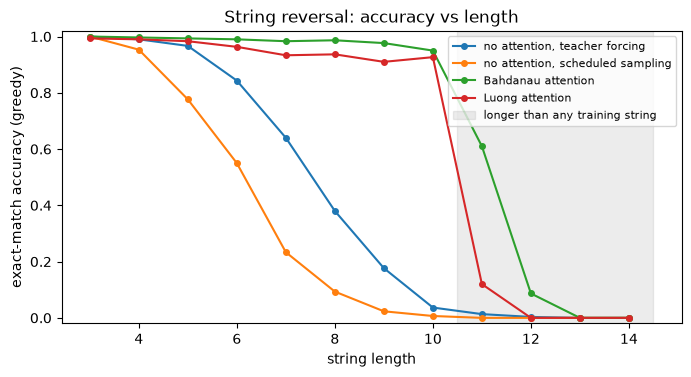

length                               4      6      8      10     12   14
no attention, teacher forcing     0.990  0.843  0.380  0.037  0.003  0.0
no attention, scheduled sampling  0.953  0.550  0.093  0.007  0.000  0.0
Bahdanau attention                0.997  0.990  0.987  0.950  0.087  0.0
Luong attention                   0.990  0.963  0.937  0.927  0.000  0.0


In [14]:
lengths = list(range(3, 15))
acc = pd.DataFrame({name: [exact_match(m, L) for L in lengths] for name, m in models.items()}, index=lengths)
acc.index.name = "length"
plt.figure(figsize=(8, 3.8))
for name in acc.columns:
    plt.plot(acc.index, acc[name], "o-", ms=4, label=name)
plt.axvspan(10.5, 14.5, color="gray", alpha=0.15, label="longer than any training string")
plt.xlabel("string length"); plt.ylabel("exact-match accuracy (greedy)"); plt.ylim(-0.02, 1.02)
plt.title("String reversal: accuracy vs length"); plt.legend(fontsize=8); plt.show()
print(acc.loc[[4, 6, 8, 10, 12, 14]].T)

**What just happened?** All four models are trained for the same 600 steps on strings of length 3-10.

- **Without attention**, accuracy drops sharply as strings get longer: the whole input must be squeezed into a single 64-number vector (the **bottleneck**), and the first output letter depends on the *last* input letter while the last output letter depends on the *first* input letter, far away in time.
- **Scheduled sampling** did not help in this run; compare its column with teacher forcing. On a short, deterministic task exposure bias is a small effect, and feeding in its own early mistakes makes the training signal noisier. It tends to matter more for long, open-ended generation; modern systems mostly train with plain teacher forcing.
- **With attention** (either kind) accuracy stays high across the training lengths, because each output step can look directly at the one input position it needs. Beyond the training range (shaded) every model degrades: length generalisation is hard for all of them.

### 6.1 What the attention looks at

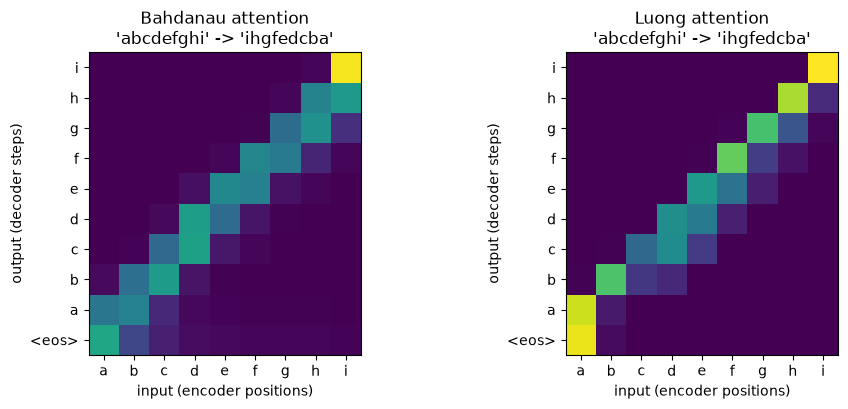

In [15]:
example = "abcdefghij"[:9]
src = torch.tensor([[s2i[c] for c in example]]); lens = torch.tensor([len(example)])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, name in zip(axes, ["Bahdanau attention", "Luong attention"]):
    pred, alphas = models[name].greedy(src, lens, len(example) + 1)
    A = torch.cat([a for a in alphas], 0).numpy()                    # (output steps, input positions)
    ax.imshow(A, cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(len(example))); ax.set_xticklabels(list(example))
    out = [i2s.get(int(i), "<eos>") for i in pred[0]]
    ax.set_yticks(range(len(out))); ax.set_yticklabels(out)
    ax.set_xlabel("input (encoder positions)"); ax.set_ylabel("output (decoder steps)")
    ax.set_title(f"{name}\n'{example}' -> '{decode_str(pred[0])}'")
plt.tight_layout(); plt.show()

**What just happened?** The heat-maps show a clear **anti-diagonal**: to write the 1st output letter the decoder attends to the last input letter, for the 2nd output letter to the second-to-last, and so on. Nobody told the model to do that; it discovered the alignment because attending to the right position makes the loss smallest. In machine translation the same plot shows word alignments between two languages.

> 🎓 **Exam / interview tip:** additive (Bahdanau) attention uses a small MLP to score each pair and costs $O(S\cdot H)$ per decoder step with an extra hidden layer; multiplicative (Luong, and the **scaled dot-product** in Transformers) is a matrix product, which is faster on GPUs. Transformers divide by $\sqrt{d_k}$ so that dot products of large vectors do not saturate the softmax.

## 7. Greedy vs beam search

> 💬 **In plain English:** greedy decoding always picks the single most likely next token; beam search keeps the $k$ most promising partial outputs at every step, so an early "second-best" choice can still win later.

The model defines $\log p(y\mid x) = \sum_t \log p(y_t\mid y_{<t}, x)$. Greedy decoding maximises each term separately, which does not guarantee the best total. **Beam search** with width $k$:

1. Start with one hypothesis `[SOS]`, score 0.
2. At each step, extend every unfinished hypothesis by every token, add the token's log-probability, and keep the best $k$ overall.
3. A hypothesis that emits `EOS` is finished; stop when $k$ hypotheses have finished or a length limit is reached.
4. Return the finished hypothesis with the highest score (optionally **length-normalised**, $\text{score}/|y|^\alpha$, because summing negative log-probs favours short outputs).

Cost: $O(k\cdot|V|)$ candidates per step instead of $O(|V|)$. $k=1$ is exactly greedy. See also [`07_NLP/05_language_models_and_generation.ipynb`](../07_NLP/05_language_models_and_generation.ipynb) for sampling-based decoding (top-k, nucleus).

In [16]:
@torch.no_grad()
def beam_search(model, src, length, k=3, max_len=None):
    # src: (1, S). Returns (best token list, its total log-prob).
    max_len = max_len or src.shape[1] + 2
    enc_out, s = model.enc(src, torch.tensor([length]))
    mask = src != PAD; keys = model.dec.keys(enc_out)
    beams = [([], 0.0, s)]                                   # (tokens so far, log-prob, decoder state)
    finished = []
    for _ in range(max_len):
        prev = torch.tensor([b[0][-1] if b[0] else SOS for b in beams])
        states = torch.cat([b[2] for b in beams], 0)
        n = len(beams)
        logits, new_s, _ = model.dec.step(prev, states, enc_out.expand(n, -1, -1), mask.expand(n, -1),
                                          None if keys is None else keys.expand(n, -1, -1))
        logp = F.log_softmax(logits, -1)                     # (n, V)
        cand = []
        for b in range(n):
            top_lp, top_id = logp[b].topk(k)                 # only the k best extensions of each beam can survive
            for lp, tok in zip(top_lp.tolist(), top_id.tolist()):
                cand.append((beams[b][0] + [tok], beams[b][1] + lp, new_s[b:b + 1]))
        cand.sort(key=lambda c: c[1], reverse=True)
        beams = []
        for c in cand[:k]:
            (finished if c[0][-1] == EOS else beams).append(c)
        if len(finished) >= k or not beams:
            break
    pool = finished if finished else beams
    best = max(pool, key=lambda c: c[1])
    return best[0], best[1]


@torch.no_grad()
def sequence_logprob(model, src, length, tokens):
    # log p(tokens | src) under teacher forcing
    tgt = torch.tensor([tokens])
    logits = model(src, torch.tensor([length]), tgt)
    return F.log_softmax(logits, -1)[0, torch.arange(len(tokens)), tgt[0]].sum().item()

rows = {}
model = models["no attention, teacher forcing"]
rng = np.random.default_rng(7)
for L in [7, 9]:
    src_b, lens_b, tgt_b = make_reverse_batch(150, L, L, rng)
    for k in [1, 3, 5]:
        correct, total_lp = 0, 0.0
        for i in range(len(src_b)):
            toks, lp = beam_search(model, src_b[i:i + 1], L, k=k)
            truth = tgt_b[i, :L + 1].tolist()
            correct += toks == truth; total_lp += lp
        rows[(L, f"k={k}" + (" (greedy)" if k == 1 else ""))] = {"exact match": correct / len(src_b), "mean log p(output)": total_lp / len(src_b)}
print("no-attention model, 150 strings per length:")
print(pd.DataFrame(rows).T)

# Sanity check: beam search with k=1 equals the batched greedy decoder
src_b, lens_b, tgt_b = make_reverse_batch(20, 8, 8, np.random.default_rng(1))
greedy_batch, _ = model.greedy(src_b, lens_b, 10)                  # same length limit as beam_search (S + 2)
same = 0
for i in range(20):
    toks, _ = beam_search(model, src_b[i:i + 1], 8, k=1)
    same += toks == greedy_batch[i].tolist()[:len(toks)]           # greedy keeps going after EOS; compare up to EOS
print(f"k=1 beam search equals greedy decoding on {same}/20 strings")

no-attention model, 150 strings per length:
                exact match  mean log p(output)
7 k=1 (greedy)        0.620              -1.506
  k=3                 0.667              -1.449
  k=5                 0.660              -1.449
9 k=1 (greedy)        0.240              -2.822
  k=3                 0.280              -2.657
  k=5                 0.280              -2.649
k=1 beam search equals greedy decoding on 20/20 strings


**What just happened?** Beam search always finds outputs whose **model log-probability** is at least as high on average as greedy decoding (the "mean log p" column rises with $k$), because it explores more candidates. Whether a higher model score also means more *correct* outputs depends on how good the model is: compare the exact-match column. Here beam search also fixes a few strings (exact match rises by a few points), but most errors remain: when the model's best-scoring sequence is wrong, a better search cannot fix it. This is the distinction between **search errors** (beam search helps) and **model errors** (it does not). Going from $k=3$ to $k=5$ barely changes anything, which is typical: small beams capture most of the gain.

> ⚠️ **Common mistake:** expecting beam search to improve open-ended text generation. For chatbots and story writing, maximising probability produces bland, repetitive text, so LLMs usually *sample* (temperature, top-p). Beam search remains standard where there is one right answer: translation, speech recognition, structured outputs.

## 8. Gradient clipping, truncated BPTT, and which architecture to choose

> 💬 **In plain English:** clipping puts a speed limit on each update so that one exploding gradient cannot wreck the model.

**Clipping by global norm** (Pascanu et al., 2013): compute $\lVert g\rVert = \sqrt{\sum_{p}\lVert g_p\rVert^2}$ over *all* parameters; if it exceeds a threshold $\tau$, rescale every gradient by $\tau/\lVert g\rVert$. The direction is unchanged; only the step length is capped. (Clipping each value separately, `clip_grad_value_`, changes the direction and is less common.)

In [17]:
def clip_global_norm(params, max_norm):
    params = [p for p in params if p.grad is not None]
    total = torch.sqrt(sum((p.grad ** 2).sum() for p in params))      # one norm over all parameters
    scale = max_norm / (total + 1e-6)
    if scale < 1:
        for p in params:
            p.grad.mul_(scale)                                         # same factor for every tensor
    return total

def exploding_rnn_grads(seed=0):
    torch.manual_seed(seed)
    rnn = nn.RNN(4, 32, batch_first=True)
    with torch.no_grad():
        rnn.weight_hh_l0.mul_(6.0)                                     # deliberately too-large recurrent weights
    loss = rnn(torch.randn(8, 50, 4))[0].pow(2).mean()
    loss.backward()
    return rnn

a, b = exploding_rnn_grads(), exploding_rnn_grads()
norm_a = clip_global_norm(a.parameters(), 1.0)
norm_b = nn.utils.clip_grad_norm_(b.parameters(), 1.0)
after = torch.sqrt(sum((p.grad ** 2).sum() for p in a.parameters()))
print(f"gradient norm before clipping: ours {norm_a:.2f}, torch {norm_b:.2f};  after clipping: {after:.4f}")
print("ours == torch.nn.utils.clip_grad_norm_:", all(torch.allclose(p.grad, q.grad) for p, q in zip(a.parameters(), b.parameters())))

gradient norm before clipping: ours 49966.21, torch 49966.21;  after clipping: 1.0000
ours == torch.nn.utils.clip_grad_norm_: True


**What just happened?** Our clipping function returns the same pre-clipping norm as PyTorch's `clip_grad_norm_` and leaves identical gradients with a total norm of 1. We used it (via PyTorch) in every training loop of this notebook; for RNNs a threshold between 0.25 and 5 is typical.

**Truncated BPTT, summarised.**

| | Full BPTT | Truncated BPTT ($k$ steps) |
|---|---|---|
| Forward context | whole sequence | whole sequence (state is carried) |
| Gradient horizon | whole sequence | last $k$ steps only |
| Memory | $O(T)$ | $O(k)$ |
| Risk | memory blow-up, exploding gradients on long $T$ | cannot learn dependencies longer than $k$ through gradients |

### 8.1 RNNs vs Transformers vs state-space models (2026)

| | RNN / LSTM / GRU | Transformer (self-attention) | State-space models (S4, Mamba, Mamba-2) and modern RNNs (RWKV, xLSTM) |
|---|---|---|---|
| Training parallel over time? | no (step by step) | **yes** | **yes** (convolution or parallel scan) |
| Cost of a length-$T$ sequence | $O(T)$ | $O(T^2)$ attention | $O(T)$ or $O(T\log T)$ |
| Generating one new token | $O(1)$, fixed-size state | $O(T)$, KV-cache grows with context | $O(1)$, fixed-size state |
| Exact recall of distant tokens | weak | **strong** (direct look-up) | weaker than attention (compressed state) |
| Typical use today | small/embedded models, streaming sensors, some time series | LLMs, translation, vision, speech | long sequences (genomics, audio), and **hybrids** with attention layers (e.g. Jamba, 2024) |

Rule of thumb: start with a Transformer for language; consider an LSTM/GRU for small streaming problems on tiny devices; consider SSM/hybrid models when sequences are very long and inference memory matters.

## 9. How this connects to modern AI

> 💬 **In plain English:** the ideas here (memory, attention, decoding, masking) are still inside every LLM; only the recurrent part has mostly been replaced.

| What you built here | Where it lives today |
|---|---|
| Next-character language model, temperature | GPT-style LLMs are next-*token* models; temperature/top-p sampling is the same knob ([`08_LLM/00_start_here_how_llms_work.ipynb`](../08_LLM/00_start_here_how_llms_work.ipynb)) |
| Teacher forcing | how every LLM is trained: predict token $t$ from the true tokens $<t$, all positions in parallel |
| Bahdanau/Luong attention | became **self-attention** in the Transformer, "Attention Is All You Need" (2017) ([`05_transformers_architecture.ipynb`](05_transformers_architecture.ipynb)) |
| Padding masks, packed sequences | attention masks and sequence packing in LLM training and batched inference servers |
| Beam search | still used in machine translation and speech recognition (e.g. Whisper supports beam search) and in constrained/structured decoding |
| Gradient clipping | standard in LLM training recipes (often global-norm 1.0) |
| Fixed-size recurrent state | the motivation for state-space models and linear-attention RNNs that compete with Transformers on long contexts |

Related notebooks: [`04_Forecasting/04_deep_learning_forecasting.ipynb`](../04_Forecasting/04_deep_learning_forecasting.ipynb) (LSTMs for time series), [`07_NLP/05_language_models_and_generation.ipynb`](../07_NLP/05_language_models_and_generation.ipynb) (n-gram LMs and decoding strategies).

## 10. Recap

- An RNN applies the same cell at every step, $h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b)$; **BPTT** is backprop on the unrolled graph, and shared weights **accumulate** gradients over time.
- $\partial h_T/\partial h_t$ is a product of $T-t$ Jacobians, so gradients **vanish or explode exponentially**; clipping fixes explosions, gating fixes (much of) vanishing.
- **LSTM** (i, f, g, o gates; additive cell state) and **GRU** (r, z gates; 3 blocks, fewer parameters) keep gradients alive over longer ranges. Our scratch cells match PyTorch exactly.
- A **character LM** predicts the next symbol; **truncated BPTT** carries the state but cuts the gradient every $k$ steps; **temperature** trades safety for diversity.
- With variable lengths, use **packing** or **masks**; never let PAD tokens leak into states, pooling or losses.
- **Seq2seq** suffers from the single-vector **bottleneck**; **attention** (Bahdanau additive / Luong multiplicative) removes it and learns alignments; we saw the anti-diagonal for string reversal.
- **Beam search** finds higher-probability outputs than greedy; it fixes search errors, not model errors.
- Today: Transformers dominate language; RNN ideas live on in state-space models and hybrids.

## Practice problems

**1. (Easy, conceptual)** Why does an RNN have the same number of parameters for sequences of length 10 and 10,000? What *does* grow with the length during training?

<details><summary>Show solution</summary>

The same $W_{xh}, W_{hh}, b$ are reused at every time step (weight sharing over time). What grows is computation ($O(T)$ steps) and, for BPTT, **memory**: all $T$ hidden states (and gate activations for LSTM/GRU) must be stored for the backward pass. Truncated BPTT caps this at $k$ steps.
</details>

**2. (Easy, calculation)** Give the number of parameters of a single-layer RNN, GRU and LSTM with input size 100 and hidden size 256 (PyTorch convention with two bias vectors). Check with code.

<details><summary>Show solution</summary>

Per gate block: $HD + H^2 + 2H = 25{,}600 + 65{,}536 + 512 = 91{,}648$. RNN: 91,648; GRU: $3\times$ = 274,944; LSTM: $4\times$ = 366,592.

```python
import torch.nn as nn

def rnn_family_params(kind, D, H):
    blocks = {"RNN": 1, "GRU": 3, "LSTM": 4}[kind]
    return blocks * (H * D + H * H + 2 * H)       # W_ih, W_hh, b_ih, b_hh per block

for kind, cls in [("RNN", nn.RNN), ("GRU", nn.GRU), ("LSTM", nn.LSTM)]:
    formula = rnn_family_params(kind, 100, 256)
    actual = sum(p.numel() for p in cls(100, 256).parameters())
    print(kind, formula, actual)
    assert formula == actual
```
</details>

**3. (Medium, conceptual)** An RNN with $\lVert W_{hh}\rVert = 0.8$ and tanh activations has to use information from 50 steps ago. Give an upper bound on how much the gradient is scaled over those 50 steps, and name two remedies.

<details><summary>Show solution</summary>

$\lVert\partial h_T/\partial h_{T-50}\rVert \le (\max|\tanh'|\cdot\lVert W_{hh}\rVert)^{50} \le 0.8^{50} \approx 1.4\times10^{-5}$, so the gradient is at least about 70,000× weaker. Remedies: gated cells (LSTM/GRU) with forget-gate bias near 1; attention or skip connections that create short gradient paths; orthogonal/identity initialisation of $W_{hh}$; for very long ranges, Transformers or state-space models.
</details>

**4. (Medium, conceptual)** In a GRU, what happens if the update gate $z_t$ is exactly 1 for all $t$? And if it is exactly 0?

<details><summary>Show solution</summary>

$h_t = (1-z_t)n_t + z_t h_{t-1}$. With $z_t = 1$: $h_t = h_{t-1}$, the state is copied unchanged forever (perfect memory, ignores the input; gradient $\partial h_t/\partial h_{t-1} = I$). With $z_t = 0$: $h_t = n_t$, the GRU behaves like a plain RNN-style update (with a reset gate), and forgets as quickly as one.
</details>

**5. (Medium, coding)** Implement a **bidirectional** RNN from two `nn.RNNCell`s and verify it against `nn.RNN(..., bidirectional=True)` with copied weights.

<details><summary>Show solution</summary>

```python
import torch, torch.nn as nn

class BiRNNScratch(nn.Module):
    # Bidirectional RNN: one cell reads left->right, another right->left; outputs are concatenated.
    def __init__(self, D, H):
        super().__init__()
        self.fwd, self.bwd = nn.RNNCell(D, H), nn.RNNCell(D, H)
    def forward(self, x):                      # x: (B, T, D)
        B, T, _ = x.shape
        h_f = h_b = x.new_zeros(B, self.fwd.hidden_size)
        outs_f, outs_b = [], [None] * T
        for t in range(T):
            h_f = self.fwd(x[:, t], h_f); outs_f.append(h_f)
        for t in reversed(range(T)):
            h_b = self.bwd(x[:, t], h_b); outs_b[t] = h_b
        return torch.cat([torch.stack(outs_f, 1), torch.stack(outs_b, 1)], -1)

torch.manual_seed(0)
D, H = 3, 4
ours = BiRNNScratch(D, H).double()
ref = nn.RNN(D, H, batch_first=True, bidirectional=True).double()
with torch.no_grad():
    for cell, sfx in [(ours.fwd, ""), (ours.bwd, "_reverse")]:
        cell.weight_ih.copy_(getattr(ref, "weight_ih_l0" + sfx)); cell.weight_hh.copy_(getattr(ref, "weight_hh_l0" + sfx))
        cell.bias_ih.copy_(getattr(ref, "bias_ih_l0" + sfx)); cell.bias_hh.copy_(getattr(ref, "bias_hh_l0" + sfx))
x = torch.randn(2, 6, D, dtype=torch.double)
diff = (ours(x) - ref(x)[0]).abs().max().item()
print("max diff vs nn.RNN(bidirectional=True):", diff)
assert diff < 1e-12
```
</details>

**6. (Medium, coding)** Write scaled dot-product attention for one query per example with a padding mask, and show that padded keys get weight 0 and do not change the context vector.

<details><summary>Show solution</summary>

```python
import torch, math

def masked_dot_attention(q, K, V, mask):
    # q: (B, d), K, V: (B, S, d), mask: (B, S) True for real tokens. Returns context (B, d) and weights (B, S).
    scores = torch.einsum("bd,bsd->bs", q, K) / math.sqrt(q.shape[-1])
    weights = scores.masked_fill(~mask, float("-inf")).softmax(-1)
    return torch.einsum("bs,bsd->bd", weights, V), weights

torch.manual_seed(0)
B, S, d = 2, 5, 8
q, K, V = torch.randn(B, d), torch.randn(B, S, d), torch.randn(B, S, d)
mask = torch.tensor([[True] * 5, [True, True, True, False, False]])
ctx, w = masked_dot_attention(q, K, V, mask)
print(w)
assert torch.allclose(w.sum(-1), torch.ones(B)) and (w[1, 3:] == 0).all()
# padding must not change the result: drop the padded keys and compare
ctx2, _ = masked_dot_attention(q[1:], K[1:, :3], V[1:, :3], mask[1:, :3])
assert torch.allclose(ctx[1], ctx2[0])
print("masked positions get weight 0 and do not affect the context")
```
</details>

**7. (Hard, conceptual)** Explain exposure bias. Why does teacher forcing cause it, how does scheduled sampling try to fix it, and why might scheduled sampling not help (as in our run)?

<details><summary>Show solution</summary>

Teacher forcing trains $p(y_t\mid y^{true}_{<t}, x)$, but at inference the model conditions on its **own** previous outputs; it never learned to recover from its own mistakes, so one early error can derail the rest (exposure bias). Scheduled sampling feeds the model's predictions during training with increasing probability, so it sees its own errors. Drawbacks: the training targets stay the ground-truth tokens even after the model's prefix diverged (an inconsistent objective, criticised by Huszár, 2015), sampling makes training noisier and sequential, and on short, deterministic tasks exposure bias is small anyway.
</details>

**8. (Hard, design)** You must build a keyword-spotting model that runs on a microcontroller, listening to an audio feature stream continuously. Would you pick an LSTM/GRU, a Transformer or an SSM? Justify using compute and memory per time step.

<details><summary>Show solution</summary>

A small GRU/LSTM (or a small SSM) is the natural choice: each new audio frame costs $O(1)$ compute and memory with a fixed-size state, and the stream never has to be stored. A Transformer would need a growing KV cache (or a sliding window) and $O(\text{window})$ work per frame. GRUs are attractive on tiny devices because they have 25% fewer parameters than LSTMs; quantised to 8 bits they fit in tens of kilobytes. An SSM is also $O(1)$ per step and is worth trying if longer context is needed.
</details>

## Further reading

- Goodfellow, Bengio & Courville, *Deep Learning* (2016), Ch. 10 "Sequence Modeling: Recurrent and Recursive Nets" (free at deeplearningbook.org).
- Jurafsky & Martin, *Speech and Language Processing* (3rd ed. draft, free online), chapters on RNNs/LSTMs and on encoder-decoder models with attention.
- Original papers: Hochreiter & Schmidhuber (1997) LSTM; Cho et al. (2014) GRU / encoder-decoder; Sutskever, Vinyals & Le (2014) seq2seq; Bahdanau, Cho & Bengio (2015) additive attention; Luong, Pham & Manning (2015) multiplicative attention; Bengio et al. (2015) scheduled sampling; Pascanu, Mikolov & Bengio (2013) on exploding/vanishing gradients and clipping; Gu & Dao (2023) Mamba.
- Andrej Karpathy, "The Unreasonable Effectiveness of Recurrent Neural Networks" (blog, 2015) and Christopher Olah, "Understanding LSTM Networks" (blog, 2015).

## Next notebook

Continue with [`20_generative_models_hands_on.ipynb`](20_generative_models_hands_on.ipynb): VAEs, GANs, diffusion models and normalizing flows trained on a CPU.